In [1]:
# False: use the saved models obtained after training. True: run both training stages again.
# A new training run replaces the saved models and predictions.
RUN_TRAINING = False

*Aim*: 25 satellite images (RGBA) and corresponding 25 masks (Black-white) are provided labelling the position of roofs. 5 additional satellite images are provided (without masks). We need to build a NN and make predictions of the roof masks on the test images.

*Summary: The Notebook can be divided into two stages* 

1) We use a U-Net with an ImageNet-pretrained ResNet18 encoder, since we have few labelled images. While looking at the provided images, we found that the mask of 270.png and 278.png are the same, with the mask of 278.png not matching the roofs of the corresponding image. We remove 278.png from our analysis. This leaves 19 training images and 5 validation images. We add 10 augmented copies per training image, giving 209 images including the originals. The chosen Augmentation includes flips, rotations, small shifts and changes in size, brightness and contrast, and is applied to both images and their masks in the training set. We freeze the encoder and train the decoder and output layer using Adam with a learning rate of 0.001. We save the model with the lowest validation loss (Dice + Binary Cross Entropy).

2) We start from the saved model and unfreeze the encoder’s final block so it can learn features better suited to roofs. We reduce the learning rate to 0.0001 to make smaller weight updates and generate fresh augmented images for each epoch. The training set still contains 209 images per epoch, but the augmented copies change. We also use a smaller learning rate (0.0001) and generate fresh augmented copies of the training images on each epoch (instead of using the same fixed set for each epoch in case 1). The resulting model has better scores and is chosen for making predictions on the 5 test images. We compare both models using Dice scores on the same five validation images, then use the best saved model from the second stage to predict the five test masks.

*Running this notebook:* Set "RUN_TRAINING = True" if you want to re-train and make predictions for both the above models. Due to the randomized data augmentations, the final scores can differ. Else, keep it at the default value of "False", doing which we skip all training and the saved best models are used to calculate validation scores, show predictions, and export the five test masks to the folder "submission_predictions". 

*Saved run:* Keep "frozen_encoder_model.pth" and "fine_tuned_model.pth" alongside this notebook and the supplied "images" and "labels" folders.

## 1. Data inspection and preparation

In [2]:
import random
from pathlib import Path
import albumentations as alb
import matplotlib.pyplot as plt
import numpy as np
import segmentation_models_pytorch as smp
import torch
from PIL import Image
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, TensorDataset

In [3]:
image_folder = Path("images")
label_folder = Path("labels")
assert Path("images").exists(), "folder images doesnt exist"
assert Path("labels").exists(), "folder label_folder doesnt exist"

image_names = [x.name for x in image_folder.glob("*.png")]
label_names = [x.name for x in label_folder.glob("*.png")]
image_names.sort()
label_names.sort()

# Separate labelled images from the five test images
labelled_images = [x for x in image_names if x in label_names]
test_images = [x for x in image_names if x not in label_names]
print(" Number of satellite images: " , len(image_names))
print(" Number of supplied masks: " , len(label_names))
print(" Number of labeled image-mask pairs: " , len(labelled_images))
print(" Number of test images: " , len(test_images))
print("Names of test images:" , test_images)

 Number of satellite images:  30
 Number of supplied masks:  25
 Number of labeled image-mask pairs:  25
 Number of test images:  5
Names of test images: ['535.png', '537.png', '539.png', '551.png', '553.png']


In [4]:
# Read RGB images; the alpha channel is not used
stacked_images = np.stack([np.array(Image.open(image_folder / x).convert("RGB")) for x in labelled_images])
stacked_masks = np.stack([np.array(Image.open(label_folder / x)) for x in labelled_images])   
stacked_test = np.stack([np.array(Image.open(image_folder / x).convert("RGB")) for x in test_images])
stacked_images.shape, stacked_masks.shape, stacked_test.shape

((25, 256, 256, 3), (25, 256, 256), (5, 256, 256, 3))

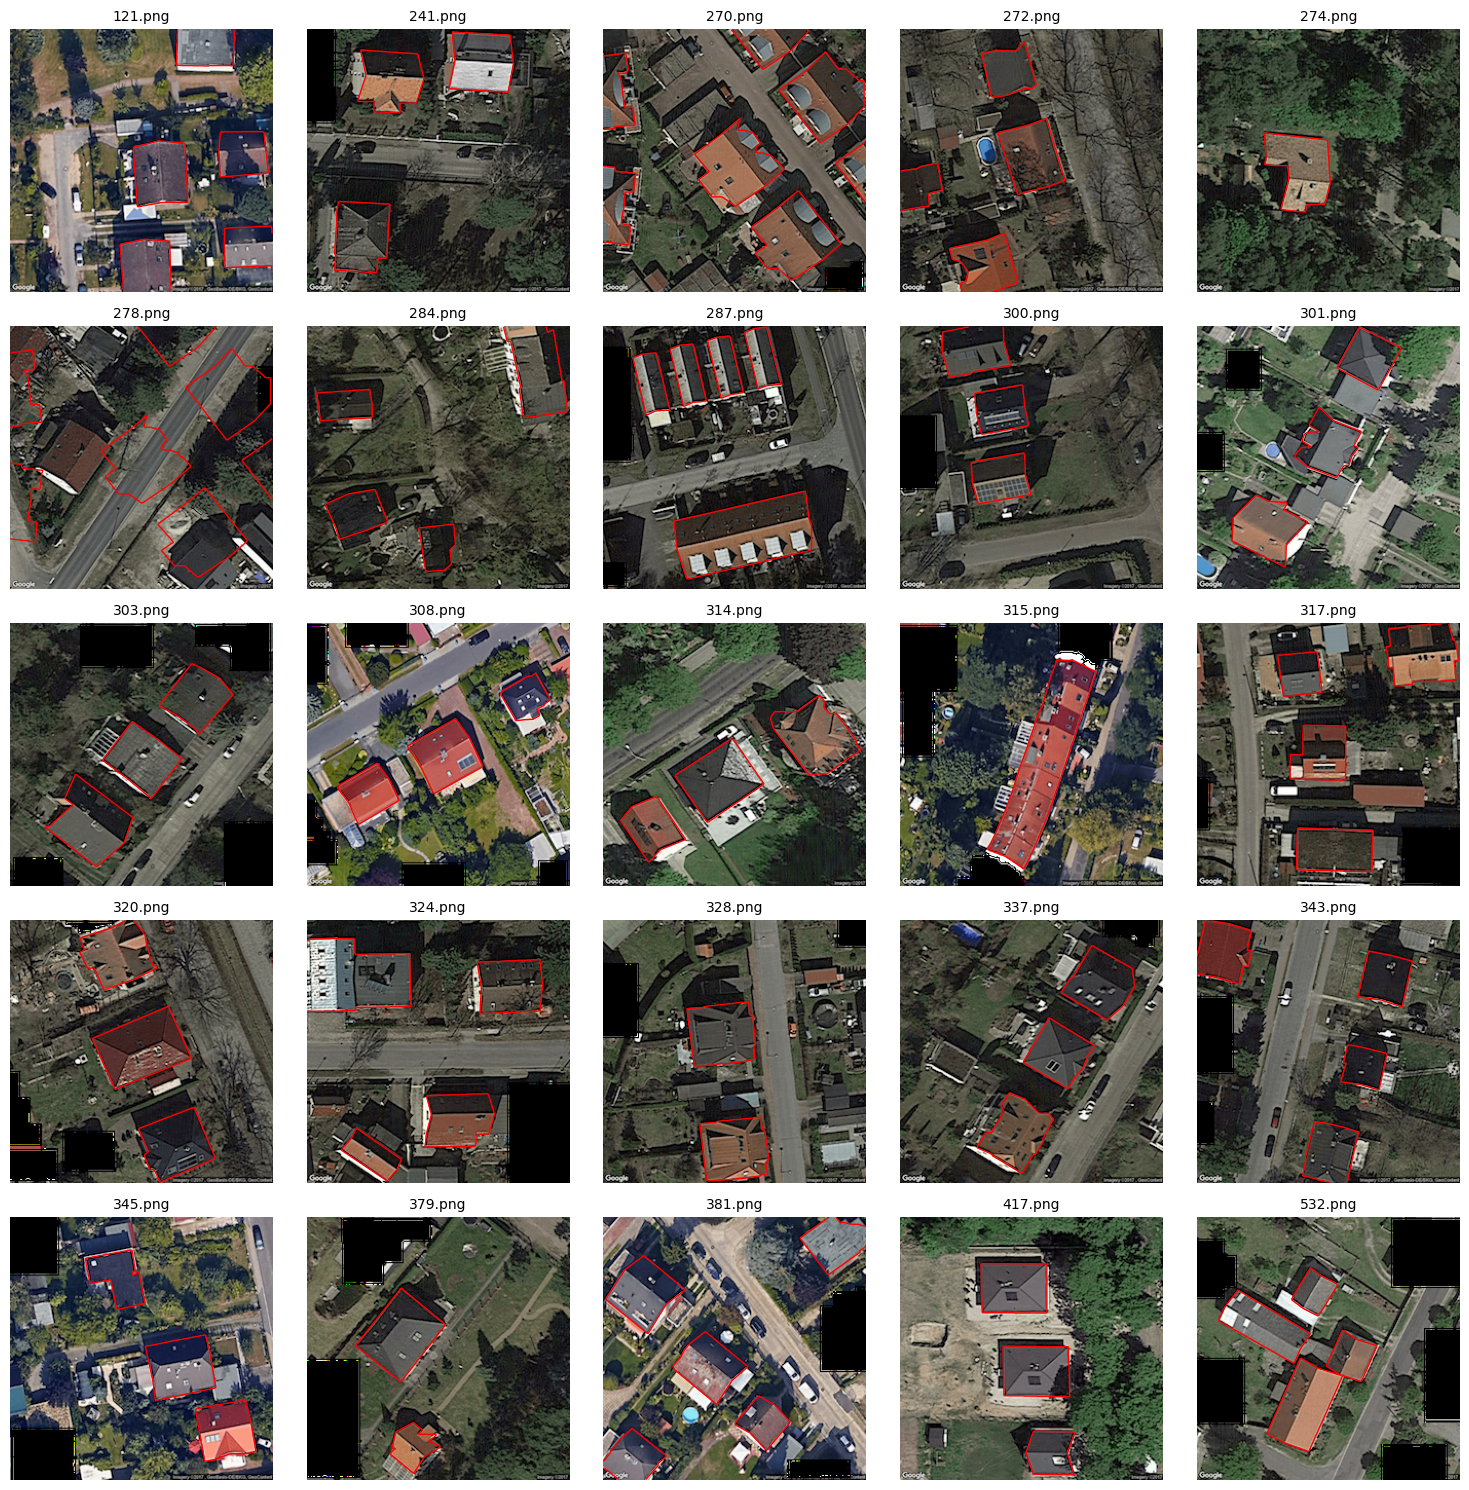

In [5]:
# Draw mask outlines to check that they match the roofs
fig, axes = plt.subplots(5, 5, figsize=(15, 15))
axes_flat = axes.ravel()
for ax, filename, img, mask in zip(axes_flat, 
                                   labelled_images, 
                                   stacked_images, 
                                   stacked_masks):
    ax.imshow(img)
    ax.contour(mask, levels=[127.5], colors="red", linewidths=1)
    ax.set_title(filename, fontsize=10)
    ax.axis("off")
plt.tight_layout()

In [6]:
# Check whether the two masks are identical
idx1 = labelled_images.index("270.png") 
idx2 = labelled_images.index("278.png")
np.array_equal(stacked_masks[idx1], stacked_masks[idx2])
# Remove 278.png because its mask does not match its roofs
usable_rgb = np.delete(stacked_images, idx2, axis=0)
usable_masks = np.delete(stacked_masks, idx2, axis=0)
usable_rgb.shape, usable_masks.shape

((24, 256, 256, 3), (24, 256, 256))

In [7]:
# Keep five images for validation before making augmented copies
train_rgb, validation_rgb, train_masks, validation_masks = train_test_split(usable_rgb, usable_masks, test_size = 5, random_state = 8)
train_rgb.shape, validation_rgb.shape, train_masks.shape, validation_masks.shape

((19, 256, 256, 3), (5, 256, 256, 3), (19, 256, 256), (5, 256, 256))

## 2. Augmentation and input preparation

Make 10 augmented copies per training image. Keep validation images unchanged.

In [8]:
# Apply spatial changes to images and masks together
transform = alb.Compose([alb.HorizontalFlip(p=0.5), 
                         alb.VerticalFlip(p=0.5), 
                         alb.RandomRotate90(p=0.5),
                         # Brightness and contrast change only the image
                         alb.RandomBrightnessContrast(contrast_limit=0.2, 
                                                      brightness_limit = 0.2,
                                                      p = 0.5),
                         # Small changes in size, position and angle
                         alb.Affine(scale=(0.9, 1.1),
                                    translate_percent=(-0.05, 0.05),
                                    rotate=(-15, 15),
                                    keep_ratio=True, p=0.5)])

In [9]:
def augment_training_data(images, masks, copies = 10, augmentation = None):
    if augmentation is None:
        augmentation = transform
    # Keep the originals, then add the augmented copies
    images_augmented = list(images)
    masks_augmented = list(masks)
    for (x,y) in zip(images, masks):
        for _ in range(copies):
            transformed = augmentation(image = x, mask = y)
            images_augmented.append(transformed["image"])
            masks_augmented.append(transformed["mask"])
    return np.stack(images_augmented), np.stack(masks_augmented)

# Use this fixed set for stage 1
aug_images, aug_masks = augment_training_data(train_rgb, train_masks) 
aug_images.shape, aug_masks.shape

((209, 256, 256, 3), (209, 256, 256))

In [10]:
def standardization(images, masks):
    # Move colour channels first and scale pixel values to 0-1
    aug_images_tensor = torch.from_numpy(images).float().permute(0,3,1,2)/255
    aug_masks_tensor = torch.from_numpy(masks).float().unsqueeze(1)/255
    # Use the normalization from ImageNet training
    imagenet_mean = torch.tensor([0.485, 0.456, 0.406]).reshape(1,3,1,1)
    imagenet_std = torch.tensor([0.229, 0.224, 0.225]).reshape(1,3,1,1)
    image_tensor = (aug_images_tensor - imagenet_mean)/imagenet_std
    return image_tensor, aug_masks_tensor

std_aug_images, std_aug_masks = standardization(aug_images, aug_masks)
std_val_images, std_val_masks = standardization(validation_rgb, validation_masks) 
std_aug_images.shape, std_aug_masks.shape, std_val_images.shape, std_val_masks.shape
# Apply the same normalization to the test images
test_tensor = torch.from_numpy(stacked_test).float().permute(0, 3, 1, 2) / 255.0
imagenet_mean = torch.tensor([0.485, 0.456, 0.406]).reshape(1, 3, 1, 1)
imagenet_std = torch.tensor([0.229, 0.224, 0.225]).reshape(1, 3, 1, 1)
normalized_test_images = (test_tensor - imagenet_mean) / imagenet_std

In [11]:
# Train in batches of four and shuffle the training images
tensor_set_train = TensorDataset(std_aug_images, std_aug_masks)
tensor_set_val = TensorDataset(std_val_images, std_val_masks)
train_data = DataLoader(tensor_set_train, batch_size = 4, shuffle = True)
val_data = DataLoader(tensor_set_val, batch_size = 4, shuffle = False)
images, masks = next(iter(train_data))
images.shape, masks.shape

(torch.Size([4, 3, 256, 256]), torch.Size([4, 1, 256, 256]))

## 3. Stage 1: encoder frozen

Train the decoder and output layer using the same augmented images each epoch.

In [12]:
# Freeze encoder weights and train the decoder and output layer
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = smp.Unet(classes=1, encoder_name = "resnet18", 
                 encoder_weights = "imagenet" if RUN_TRAINING else None, 
                 in_channels=3)
for param in model.encoder.parameters():
  param.requires_grad = False
model = model.to(device)

In [13]:
# We use BCE and Dice loss together 
binary_cross_entropy = torch.nn.BCEWithLogitsLoss()
def loss_function(model_output, correct_masks):
    bce_loss = binary_cross_entropy(model_output, correct_masks)
    roof_probabilities = torch.sigmoid(model_output)
    overlap = (roof_probabilities * correct_masks).sum()
    dice_score = ((2*overlap +1)/(roof_probabilities.sum() + correct_masks.sum() +1))
    dice_loss = 1-dice_score
    return bce_loss + dice_loss    

In [14]:
# Adam updates the weights that are being trained
optimizer = torch.optim.Adam(model.parameters(), lr = 0.001)

In [15]:
# Train for one epoch
def train_one_epoch(model, train_data, optimizer):
    model.train()
    model.encoder.eval() 
    total_loss = 0
    for batch_images, batch_masks in train_data:
        batch_images = batch_images.to(device)
        batch_masks = batch_masks.to(device)
        # Clear gradients from the previous batch
        optimizer.zero_grad() 
        model_output = model(batch_images)
        loss = loss_function(model_output, batch_masks)
        # Calculate gradients
        loss.backward() 
        # Update trainable weights
        optimizer.step() 
        # Weight each batch by its size, including the smaller final batch
        total_loss = total_loss + loss.item() * len(batch_images)
    average_loss = total_loss/ len(train_data.dataset)
    return average_loss    

In [16]:
# Measure validation loss without changing weights
def validate_one_epoch(model, val_data):
    model.eval()
    total_loss = 0
    with torch.no_grad():
        for batch_images, batch_masks in val_data:
              batch_images = batch_images.to(device)
              batch_masks = batch_masks.to(device)
              model_output = model(batch_images)
              loss = loss_function(model_output, batch_masks)
              total_loss += loss.item() * len(batch_images)
    average_loss = total_loss/ len(val_data.dataset)
    return average_loss    

In [17]:
# Train on the same augmented images in each epoch
if RUN_TRAINING:
    maximum_epochs = 40
    training_loss_history = []
    validation_loss_history = []
    best_validation_loss = float("inf")
    epochs_without_improvement = 0
    patience = 5
    epoch = 0
    while epoch < maximum_epochs:
        train_loss = train_one_epoch(model, train_data, optimizer)
        training_loss_history.append(train_loss)
        val_loss = validate_one_epoch(model, val_data)
        validation_loss_history.append(val_loss)
        # Keep the weights with the lowest validation loss
        if val_loss < best_validation_loss:
            best_validation_loss = val_loss
            epochs_without_improvement = 0
            torch.save(model.state_dict(), "frozen_encoder_model.pth")
        else:
            epochs_without_improvement += 1
        epoch += 1
        print("Epoch Number = ", epoch, ", train_loss = ", train_loss, ", val_loss = ", val_loss) 
        # Stop after five (patience) epochs without a lower validation loss
        if epochs_without_improvement == patience:
            break
else:
    print("Training with the encoder frozen skipped: using the saved best model.")

Training with the encoder frozen skipped: using the saved best model.


### Stage 1 results

Check the predicted masks and validation Dice scores.

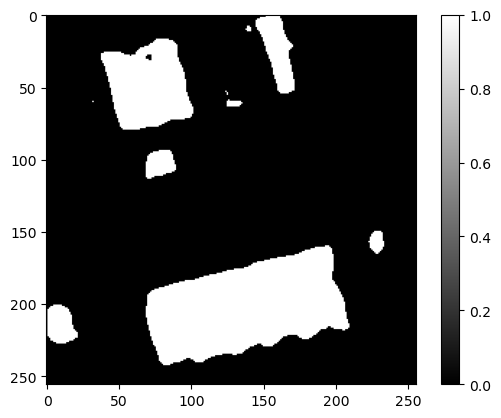

In [18]:
# Load the best weights from stage 1
best_model_weights = torch.load("frozen_encoder_model.pth", map_location=device, weights_only=True)
model.load_state_dict(best_model_weights)
model.eval()
with torch.no_grad():
    val_img_on_device = std_val_images.to(device)
    val_output = model(val_img_on_device)
    val_prob = torch.sigmoid(val_output) # Convert outputs to probabilities
    predicted_val_masks = (val_prob >= 0.5) # Mark probabilities of 0.5 or more as roof
    plt.imshow(predicted_val_masks[0][0].cpu().numpy(), cmap = "gray", vmin = 0, vmax =1)
    plt.colorbar()

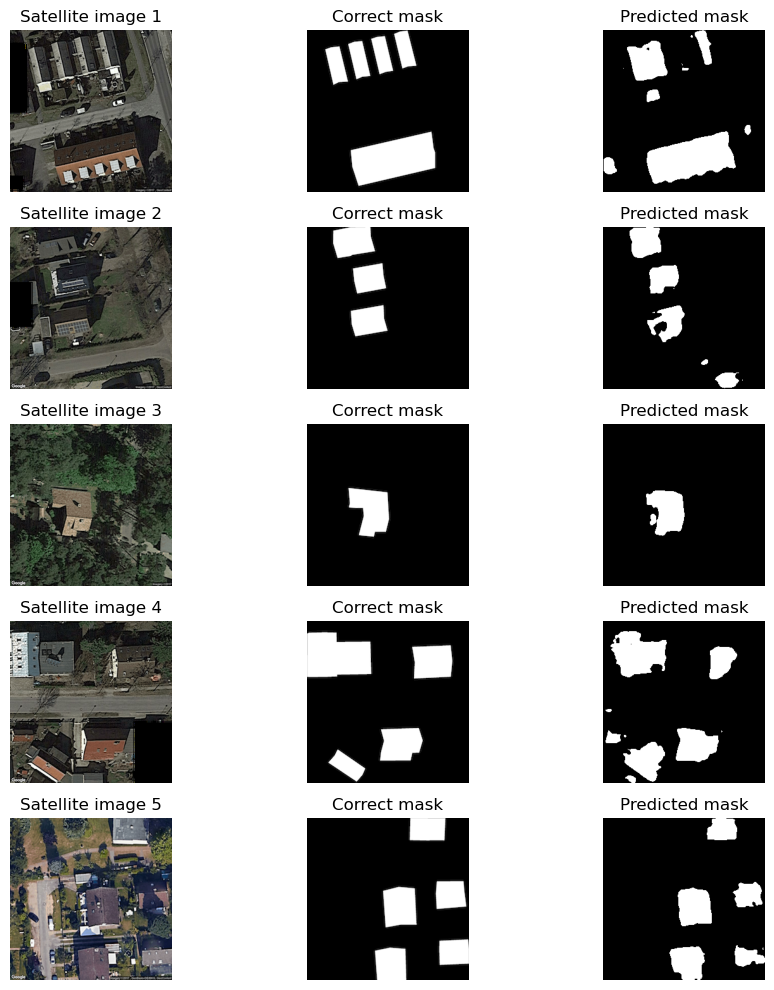

In [19]:
# Compare each prediction with its supplied mask
number_of_images = len(validation_rgb)
fig, axes = plt.subplots(number_of_images, 3, figsize=(10, 2 * number_of_images), squeeze=False)
for i in range(number_of_images):
    axes[i, 0].imshow(validation_rgb[i])
    axes[i, 0].set_title(f"Satellite image {i + 1}")
    axes[i, 1].imshow(validation_masks[i], cmap="gray", vmin=0, vmax=255)
    axes[i, 1].set_title("Correct mask")
    axes[i, 2].imshow(
        predicted_val_masks[i, 0].cpu().numpy(),
        cmap="gray",
        vmin=0,
        vmax=1
    )
    axes[i, 2].set_title("Predicted mask")
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.show()

In [20]:
# Dice measures mask overlap: 1 is a perfect match
true_masks = std_val_masks.to(device) >= 0.5
# Sum over channels, height and width to score each image
predicted_roof_pixels = predicted_val_masks.sum(dim=(1, 2, 3))
actual_roof_pixels = true_masks.sum(dim=(1, 2, 3))
total_roof_pixels = predicted_roof_pixels + actual_roof_pixels
# Count pixels marked as roof in both masks
intersection = (predicted_val_masks & true_masks).sum(dim = (1,2,3))
dice_score = (2*intersection)/(total_roof_pixels)
print("Dice per validation image:", dice_score.cpu().numpy())
print("Mean validation Dice:", dice_score.mean().item())

Dice per validation image: [0.8017692  0.7764215  0.89456296 0.7705782  0.8630274 ]
Mean validation Dice: 0.8212718963623047


## 4. Stage 2: fine-tune the final encoder block

Start from the best model from stage 1. Use a smaller learning rate and fresh augmented images each epoch.

In [21]:
# Start from the best weights from stage 1
fine_tune_checkpoint = Path("fine_tuned_model.pth")
fine_tune_seed = 108
if RUN_TRAINING:
    random.seed(fine_tune_seed)
    np.random.seed(fine_tune_seed)
    torch.manual_seed(fine_tune_seed)
    best_model_weights = torch.load("frozen_encoder_model.pth", map_location=device, weights_only=True)
    model.load_state_dict(best_model_weights)
    for param in model.encoder.parameters():
        param.requires_grad = False
    # Unfreeze the final encoder block; the decoder still trains
    for param in model.encoder.layer4.parameters():
        param.requires_grad = True
    fine_tune_optimizer = torch.optim.Adam(model.parameters(), lr=0.0001) # Smaller steps
else:
    print("Fine-tuning disabled: using the saved model and loss history.")

Fine-tuning disabled: using the saved model and loss history.


In [22]:
# Store the best weights and the losses from every epoch
fine_tune_epochs = 15
fine_tune_patience = 5
def save_fine_tune_checkpoint(save_weights):
    # Keep earlier best weights if this epoch did not improve
    if save_weights:
        best_weights = model.state_dict()
    else:
        saved = torch.load(fine_tune_checkpoint, map_location="cpu", weights_only=True)
        best_weights = saved["model_state_dict"]
    history = {
        "seed": fine_tune_seed,
        "starting_validation_loss": fine_tune_starting_loss,
        "training_loss": fine_tune_training_history,
        "validation_loss": fine_tune_validation_history,
        "best_epoch": fine_tune_best_epoch,
        "best_validation_loss": fine_tune_best_loss,
        "epochs_without_improvement": fine_tune_epochs_without_improvement,
    }
    torch.save({"model_state_dict": best_weights, "history": history}, fine_tune_checkpoint)

if RUN_TRAINING:
    fine_tune_training_history, fine_tune_validation_history = [], []
    fine_tune_starting_loss = validate_one_epoch(model, val_data)
    fine_tune_best_loss = fine_tune_starting_loss
    fine_tune_best_epoch = 0
    fine_tune_epochs_without_improvement = 0
    # Keep the starting model if fine-tuning does not improve it
    save_fine_tune_checkpoint(save_weights=True)
else:
    # Reload losses so the plots work without retraining
    saved = torch.load(fine_tune_checkpoint, map_location="cpu", weights_only=True)
    history = saved["history"]
    fine_tune_seed = history["seed"]
    fine_tune_starting_loss = history["starting_validation_loss"]
    fine_tune_training_history = history["training_loss"]
    fine_tune_validation_history = history["validation_loss"]
    fine_tune_best_epoch = history["best_epoch"]
    fine_tune_best_loss = history["best_validation_loss"]
    fine_tune_epochs_without_improvement = history["epochs_without_improvement"]
    print(f"Loaded {len(fine_tune_training_history)} epochs of history from the checkpoint; "
          f"best fine-tuning epoch: {fine_tune_best_epoch}.")


Loaded 13 epochs of history from the checkpoint; best fine-tuning epoch: 8.


In [23]:
# Repeat training with fresh augmented images each epoch
if RUN_TRAINING:
    fine_tune_epoch = 0
    while fine_tune_epoch < fine_tune_epochs:
        epoch_images, epoch_masks = augment_training_data(train_rgb, train_masks)
        epoch_image_tensors, epoch_mask_tensors = standardization(epoch_images, epoch_masks)
        epoch_dataset = TensorDataset(epoch_image_tensors, epoch_mask_tensors)
        epoch_train_data = DataLoader(epoch_dataset, batch_size=4, shuffle=True)
        train_loss = train_one_epoch(model, epoch_train_data, fine_tune_optimizer)
        val_loss = validate_one_epoch(model, val_data)
        fine_tune_training_history.append(train_loss)
        fine_tune_validation_history.append(val_loss)
        fine_tune_epoch += 1

        improved = val_loss < fine_tune_best_loss
        if improved:
            fine_tune_best_loss = val_loss
            fine_tune_best_epoch = fine_tune_epoch
            fine_tune_epochs_without_improvement = 0
        else:
            fine_tune_epochs_without_improvement += 1

        save_fine_tune_checkpoint(save_weights=improved) # Update the loss history every epoch
        print(f"Epoch {fine_tune_epoch:02d} | Training loss: {train_loss:.4f} | "
              f"Validation loss: {val_loss:.4f}", flush=True)
        # Allow five epochs without a lower validation loss
        if fine_tune_epochs_without_improvement >= fine_tune_patience:
            print("Early stopping: validation loss has stopped improving.")
            break


### Stage 2 results

Compare both stages on the same five validation images.

In [24]:
# Load the best weights from stage 2
fine_tune_saved = torch.load(fine_tune_checkpoint, map_location=device, weights_only=True)
model.load_state_dict(fine_tune_saved["model_state_dict"])
model.eval()

# Predict masks for the same validation images
with torch.no_grad():
    fine_tune_output = model(std_val_images.to(device))
    fine_tune_probabilities = torch.sigmoid(fine_tune_output)
    fine_tune_masks = fine_tune_probabilities >= 0.5

# Calculate Dice scores
true_masks = std_val_masks.to(device) >= 0.5
intersection = (fine_tune_masks & true_masks).sum(dim=(1, 2, 3))
total_roof_pixels = (fine_tune_masks.sum(dim=(1, 2, 3)) + true_masks.sum(dim=(1, 2, 3)))
fine_tune_dice_scores = ((2 * intersection) / (total_roof_pixels))

# Compare both stages on the same validation images
frozen_encoder_mean_dice = dice_score.mean().item()
fine_tune_mean_dice = fine_tune_dice_scores.mean().item()

print("Fine-tuned Dice per image:", fine_tune_dice_scores.cpu().numpy())
print(f"Encoder frozen mean Dice:   {frozen_encoder_mean_dice}")
print(f"Fine-tuned mean Dice: {fine_tune_mean_dice}")
print(f"Change in Dice:       {fine_tune_mean_dice - frozen_encoder_mean_dice:+.4f}")

Fine-tuned Dice per image: [0.81102955 0.8788051  0.83956313 0.8277152  0.9395961 ]
Encoder frozen mean Dice:   0.8212718963623047
Fine-tuned mean Dice: 0.8593418002128601
Change in Dice:       +0.0381


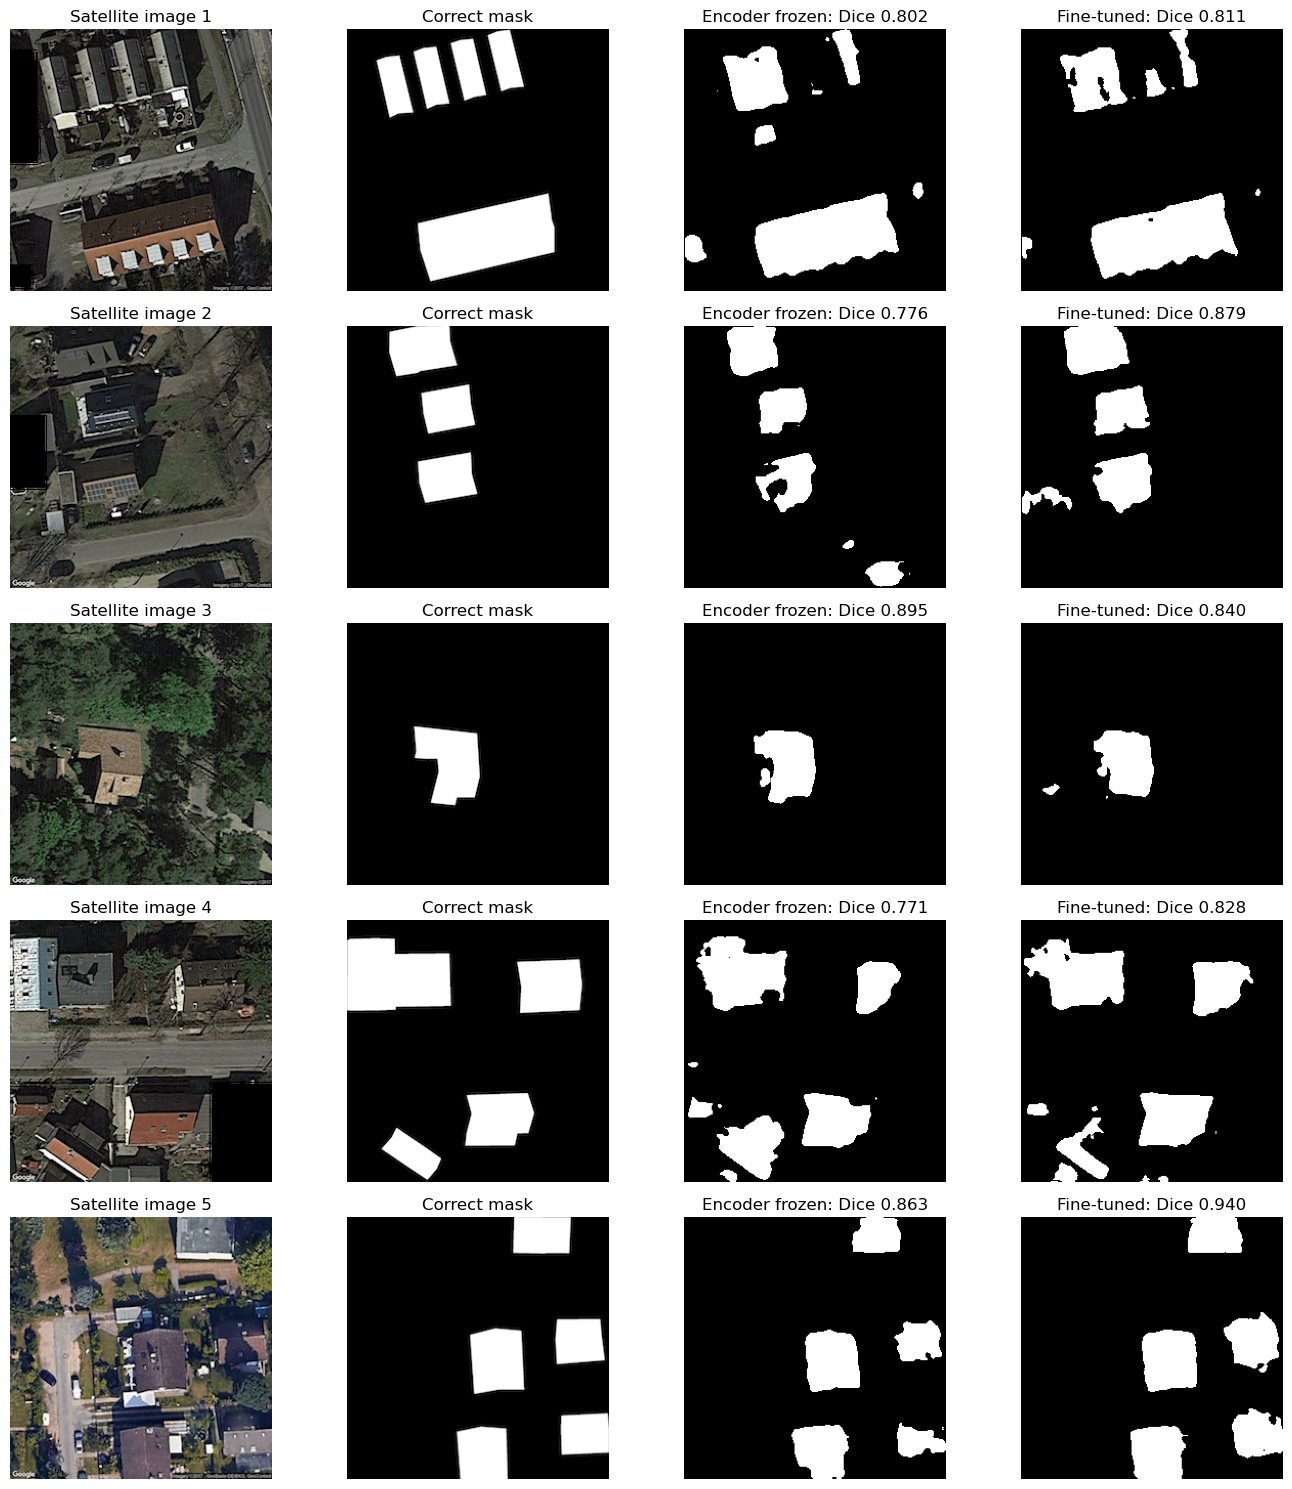

In [25]:
# Show the supplied mask and both model predictions
number_of_images = len(validation_rgb)
fig, axes = plt.subplots(number_of_images, 4,figsize=(14, 3 * number_of_images), squeeze=False)
for i in range(number_of_images):
    axes[i, 0].imshow(validation_rgb[i])
    axes[i, 0].set_title(f"Satellite image {i + 1}")
    axes[i, 1].imshow(
        validation_masks[i], cmap="gray", vmin=0, vmax=255)
    axes[i, 1].set_title("Correct mask")
    axes[i, 2].imshow(
        predicted_val_masks[i, 0].cpu().numpy(),
        cmap="gray", vmin=0, vmax=1)
    axes[i, 2].set_title(f"Encoder frozen: Dice {dice_score[i].item():.3f}")
    axes[i, 3].imshow(fine_tune_masks[i, 0].cpu().numpy(), cmap="gray", vmin=0, vmax=1)
    axes[i, 3].set_title(f"Fine-tuned: Dice {fine_tune_dice_scores[i].item():.3f}")
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 5. Test predictions

Use the saved model from the second stage to predict the five unlabelled images.

In [26]:
# Load the best weights from stage 2
fine_tune_saved = torch.load(fine_tune_checkpoint, map_location=device, weights_only=True)
model.load_state_dict(fine_tune_saved["model_state_dict"])
model.eval()
# Predict masks for the five test images
with torch.no_grad():
    test_output = model(normalized_test_images.to(device))
    test_probabilities = torch.sigmoid(test_output)
    # Remove the single mask channel and convert to NumPy
    predicted_test_masks = (
        (test_probabilities >= 0.5).squeeze(1).cpu().numpy()
    )

# Save one mask per test image using the original filename
prediction_folder = Path("submission_predictions")
prediction_folder.mkdir(exist_ok=True)

for filename, mask in zip(test_images, predicted_test_masks):
    mask_uint8 = mask.astype(np.uint8) * 255 # Roof = 255; background = 0
    Image.fromarray(mask_uint8).save(prediction_folder / filename)
    print("Saved:", prediction_folder / filename)

Saved: submission_predictions/535.png
Saved: submission_predictions/537.png
Saved: submission_predictions/539.png
Saved: submission_predictions/551.png
Saved: submission_predictions/553.png


## 6. Final Note

This was a nice problem to solve. With more time, I could try a different encoder and adjust the augmentation settings to see whether they improve validation performance. 